# Robustness checks: a stronger baseline, a corrected significance test and confidence intervals

Notebook 07 showed that ordering the quantile forecast at $\tau^*$ is 2-40% cheaper than ordering the point forecast.
A reviewer would ask three questions, and this notebook answers them.

**1. Is the point forecast a fair comparison?** No planner orders exactly the point forecast; they add a
**safety stock**. So we build a stronger baseline: the point LightGBM forecast **plus the typical error at the
level $\tau^*$**, learned from past errors:

$$q = \exp\big(\log(1 + \hat y) + e_h(\tau^*)\big) - 1$$

where $e_h(\tau^*)$ is the $\tau^*$ quantile of the log errors $\log(1+y) - \log(1+\hat y)$ of the point model at
horizon $h$. The errors come from the **10 validation weeks before the forecast origin** (the same weeks used for
tuning in notebook 05), so there is no leakage. If quantile LightGBM still beats this, the gain really comes from
the quantile model and not only from "ordering a bit more".

**2. Is the significance test right?** Notebooks 05-07 used the simple Diebold-Mariano test. The loss in one week can
be related to the next weeks, and there are only 30 test weeks. `diebold_mariano_hac` corrects for both
(Newey-West variance + Harvey-Leybourne-Newbold small-sample correction, t distribution). Every claim is checked again.

**3. How sure are the savings?** We resample the 3,597 centre-meal series 1,000 times (bootstrap) and report a 95%
confidence interval for every saving.

Running time: about 5-10 minutes (one LightGBM per fold for the validation errors).

In [1]:
import sys
sys.path.append('..')
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

from src.features import build_dataset, FEATURES
from src.folds import ORIGINS, split_fold
from src.metrics import pinball, diebold_mariano, diebold_mariano_hac
from src.simulation import TAUS, COST_RATIOS, critical_ratio, quantity_at_tau, simulate
from src.plot_settings import set_ieee_style, save_fig, ONE_COL

set_ieee_style()
pd.set_option('display.max_columns', 30)
warnings.filterwarnings('ignore')
SEED = 42

## 1. Load the data and the saved forecasts

In [2]:
df = pd.read_parquet('../data/processed/clean.parquet')
hist = pd.read_parquet('../data/processed/history_features.parquet')
data = build_dataset(df, hist)
for col in ['center_id', 'meal_id', 'city_code', 'region_code']:
    data[col] = data[col].astype('category')

keys = ['series_id', 'week', 'origin']
quantiles = pd.read_parquet('../data/processed/predictions_quantiles.parquet')
trees = pd.read_parquet('../data/processed/predictions_trees.parquet')[keys + ['LightGBM', 'XGBoost', 'Random Forest']]
baselines = pd.read_parquet('../data/processed/predictions_baselines.parquet')[keys + ['Linear Regression']]
preds = quantiles.merge(trees, on=keys).merge(baselines, on=keys)
print(data.shape, len(preds))

(4407292, 32) 98475


## 2. Safety stock baseline: errors of the point model in the validation weeks

For each fold we train the point LightGBM again on the weeks before the validation period (the same model notebook 05
used for early stopping: same settings, same number of trees), forecast the 10 validation weeks and keep the errors.

In [3]:
best_05 = pd.read_csv('../results/tables/05_best_params.csv')

# every tau we need: the 7 levels and the tau* of every cost ratio
NEEDED = sorted(set(TAUS) | {round(critical_ratio(r), 6) for r in COST_RATIOS})

error_quantiles = {}      # (origin, h) -> {tau: quantile of the log error}
for origin in ORIGINS:
    start = time.time()
    train, _ = split_fold(data, origin)
    inner_train, val = split_fold(train, origin - 10)

    row = best_05[(best_05['origin'] == origin) & (best_05['model'] == 'LightGBM')].iloc[0]
    model = lgb.LGBMRegressor(n_estimators=int(row['n_trees']), learning_rate=0.05, subsample=0.8, subsample_freq=1,
                              colsample_bytree=0.8, num_leaves=int(row['num_leaves']),
                              min_child_samples=int(row['min_child_samples']), random_state=SEED, verbose=-1)
    model.fit(inner_train[FEATURES], inner_train['log_orders'])
    log_error = val['log_orders'].values - model.predict(val[FEATURES])

    for h in range(1, 11):
        e = log_error[val['h'].values == h]
        error_quantiles[(origin, h)] = dict(zip(NEEDED, np.quantile(e, NEEDED)))
    print(f'origin {origin}: {len(val):,} validation rows, {time.time() - start:.0f} s')

# example: how much the safety stock adds at h = 1 and h = 10 (as a factor on the forecast)
for h in [1, 10]:
    q75 = error_quantiles[(135, h)][0.75]
    print(f'origin 135, h = {h}: tau 0.75 log error {q75:.3f} -> order = forecast x {np.exp(q75):.2f} (roughly)')

origin 115: 32,707 validation rows, 53 s


origin 125: 32,834 validation rows, 63 s


origin 135: 32,820 validation rows, 62 s
origin 135, h = 1: tau 0.75 log error 0.372 -> order = forecast x 1.45 (roughly)
origin 135, h = 10: tau 0.75 log error 0.435 -> order = forecast x 1.55 (roughly)


In [4]:
def safety_stock_order(rows, tau):
    # point forecast + the tau quantile of the past log errors at the same horizon
    shift = np.array([error_quantiles[(o, h)][round(tau, 6)] for o, h in zip(rows['origin'], rows['h'])])
    return np.clip(np.expm1(np.log1p(rows['LightGBM'].values) + shift), 0, None)


def order_quantity(rows, policy, r):
    tau = critical_ratio(r)
    if policy == 'Point LightGBM':
        return rows['LightGBM'].values
    if policy == 'Safety stock (LightGBM + past errors)':
        return safety_stock_order(rows, tau)
    name = {'Quantile LightGBM': 'LightGBM', 'Quantile XGBoost': 'XGBoost'}[policy]
    return quantity_at_tau(rows[[f'{name} q{t}' for t in TAUS]].values, tau)


policies = ['Point LightGBM', 'Safety stock (LightGBM + past errors)', 'Quantile XGBoost', 'Quantile LightGBM']

### The safety stock forecasts as quantile forecasts (same checks as notebook 06)

In [5]:
rows = []
for origin in ORIGINS:
    fold = preds[preds['origin'] == origin]
    y = fold['num_orders'].values
    for tau in TAUS:
        for name, q in [('Safety stock', safety_stock_order(fold, tau)),
                        ('Quantile LightGBM', fold[f'LightGBM q{tau}'].values)]:
            rows.append({'origin': origin, 'tau': tau, 'model': name,
                         'pinball': pinball(y, q, tau), 'coverage': np.mean(y <= q) * 100})
check = pd.DataFrame(rows).groupby(['tau', 'model'])[['pinball', 'coverage']].mean().unstack()
check.round(2)

pinball                       coverage             
model Quantile LightGBM Safety stock Quantile LightGBM Safety stock
tau                                                                
0.3               29.21        30.51             30.62        29.11
0.4               33.21        34.32             40.16        38.83
0.5               35.00        36.20             49.30        48.55
0.6               35.00        36.22             57.97        58.50
0.7               33.02        34.13             67.52        68.74
0.8               28.12        29.62             77.35        79.28
0.9               19.54        21.28             87.43        89.63

## 3. Cost simulation with the stronger baseline

In [6]:
rows = []
for origin in ORIGINS:
    fold = preds[preds['origin'] == origin]
    for r in COST_RATIOS:
        for policy in policies:
            result = simulate(fold['num_orders'], order_quantity(fold, policy, r), c_o=1, c_u=r)
            rows.append({'origin': origin, 'r': r, 'policy': policy, **result})
sim = pd.DataFrame(rows)
sim_mean = sim.groupby(['r', 'policy']).mean(numeric_only=True).drop(columns='origin')

cost = sim_mean['Cost'].unstack()[policies]
relative_cost = cost.div(cost['Point LightGBM'], axis=0) * 100
relative_cost.round(1)

policy,Point LightGBM,Safety stock (LightGBM + past errors),Quantile XGBoost,Quantile LightGBM
r,,,,
0.5,100.0,99.8,96.0,95.7
1.0,100.0,101.5,99.0,98.1
1.5,100.0,95.7,93.2,92.5
2.0,100.0,89.3,86.2,86.2
3.0,100.0,78.5,74.5,75.0
4.0,100.0,70.3,66.0,66.7
5.0,100.0,64.0,59.0,59.6


In [7]:
# saving of quantile LightGBM compared with the safety stock baseline, in %
saving_vs_safety = (cost['Safety stock (LightGBM + past errors)'] - cost['Quantile LightGBM']) \
                   / cost['Safety stock (LightGBM + past errors)'] * 100
saving_vs_safety.round(1)

r
0.5    4.1
1.0    3.3
1.5    3.4
2.0    3.4
3.0    4.5
4.0    5.1
5.0    6.8
dtype: float64

In [8]:
show = ['Waste %', 'Shortage %', 'Service level %']
sim_mean.loc[(3, policies), show].round(1)

Waste %  Shortage %  \
r   policy                                                       
3.0 Point LightGBM                            10.1        18.6   
    Safety stock (LightGBM + past errors)     32.0         6.6   
    Quantile XGBoost                          24.8         8.1   
    Quantile LightGBM                         24.0         8.5   

                                           Service level %  
r   policy                                                  
3.0 Point LightGBM                                    46.3  
    Safety stock (LightGBM + past errors)             74.4  
    Quantile XGBoost                                  73.9  
    Quantile LightGBM                                 73.1

## 4. Confidence intervals for the savings (bootstrap over series)

The cost of each series (centre-meal) is added up over the 3 folds. Then we draw 3,597 series with replacement,
1,000 times, and compute the saving each time. The 2.5% and 97.5% values give the 95% confidence interval.

In [9]:
series_cost = {}
for r in COST_RATIOS:
    for policy in policies:
        q = np.round(order_quantity(preds, policy, r))
        y = preds['num_orders'].values
        c = np.maximum(q - y, 0) + r * np.maximum(y - q, 0)
        series_cost[(r, policy)] = pd.Series(c).groupby(preds['series_id'].values).sum()
series_cost = pd.DataFrame(series_cost)          # one row per series, one column per (r, policy)

rng = np.random.default_rng(SEED)
n = len(series_cost)
boot = np.array([series_cost.values[rng.integers(0, n, n)].sum(axis=0) for _ in range(1000)])
boot = pd.DataFrame(boot, columns=series_cost.columns)

ci_rows = []
for r in COST_RATIOS:
    q_cost = boot[(r, 'Quantile LightGBM')]
    for base in ['Point LightGBM', 'Safety stock (LightGBM + past errors)']:
        s = (boot[(r, base)] - q_cost) / boot[(r, base)] * 100
        full = (series_cost[(r, base)].sum() - series_cost[(r, 'Quantile LightGBM')].sum()) / series_cost[(r, base)].sum() * 100
        ci_rows.append({'r': r, 'compared with': base, 'saving %': round(full, 1),
                        '95% CI low': round(np.percentile(s, 2.5), 1), '95% CI high': round(np.percentile(s, 97.5), 1)})
ci_table = pd.DataFrame(ci_rows)
ci_table

,r,compared with,saving %,95% CI low,95% CI high
0,0.5,Point LightGBM,4.3,3.6,5.0
1,0.5,Safety stock (LightGBM + past errors),4.1,3.6,4.7
2,1.0,Point LightGBM,1.9,1.4,2.4
3,1.0,Safety stock (LightGBM + past errors),3.3,2.8,3.8
4,1.5,Point LightGBM,7.5,6.8,8.1
5,1.5,Safety stock (LightGBM + past errors),3.4,2.8,3.9
6,2.0,Point LightGBM,13.8,13.0,14.5
7,2.0,Safety stock (LightGBM + past errors),3.4,2.8,4.2
8,3.0,Point LightGBM,25.0,24.1,25.8
9,3.0,Safety stock (LightGBM + past errors),4.5,3.6,5.4


## 5. Corrected Diebold-Mariano test for every claim

Weekly loss over the 30 test weeks. Simple = the version used in notebooks 05-07; corrected = Newey-West + HLN.
Negative statistic = model A is better.

In [10]:
preds['test_week'] = preds['origin'].astype(str) + '_' + preds['week'].astype(str).str.zfill(3)
y = preds['num_orders']

def weekly(loss):
    return pd.Series(loss).groupby(preds['test_week'].values).mean().sort_index()

def mae_loss(column):
    return weekly(np.abs(preds[column].values - y.values))

def pinball_loss(q, tau):
    diff = y.values - q
    return weekly(np.maximum(tau * diff, (tau - 1) * diff))

def cost_loss(policy, r):
    q = np.round(order_quantity(preds, policy, r))
    return weekly(np.maximum(q - y.values, 0) + r * np.maximum(y.values - q, 0))

tests = []
for a, b in [('LightGBM', 'Linear Regression'), ('XGBoost', 'Linear Regression'), ('Random Forest', 'Linear Regression'),
             ('LightGBM', 'XGBoost'), ('LightGBM', 'Random Forest')]:
    tests.append(('RQ1 accuracy (MAE)', a, b, mae_loss(a), mae_loss(b)))
for tau in [0.5, 0.7, 0.9]:
    tests.append((f'RQ2 pinball tau={tau}', 'Quantile LightGBM', 'Point LightGBM',
                  pinball_loss(preds[f'LightGBM q{tau}'].values, tau), pinball_loss(preds['LightGBM'].values, tau)))
for r in COST_RATIOS:
    for base in ['Point LightGBM', 'Safety stock (LightGBM + past errors)']:
        tests.append((f'RQ3 cost r={r}', 'Quantile LightGBM', base, cost_loss('Quantile LightGBM', r), cost_loss(base, r)))

dm_rows = []
for what, a, b, la, lb in tests:
    s_stat, s_p = diebold_mariano(la, lb)
    c_stat, c_p = diebold_mariano_hac(la, lb)
    dm_rows.append({'test': what, 'model A': a, 'model B': b, 'simple DM': round(s_stat, 2), 'simple p': round(s_p, 4),
                    'corrected DM': round(c_stat, 2), 'corrected p': round(c_p, 4)})
dm_table = pd.DataFrame(dm_rows)
dm_table

,test,model A,model B,simple DM,simple p,corrected DM,corrected p
0,RQ1 accuracy (MAE),LightGBM,Linear Regression,-9.38,0.0000,-7.98,0.0000
1,RQ1 accuracy (MAE),XGBoost,Linear Regression,-9.27,0.0000,-7.95,0.0000
2,RQ1 accuracy (MAE),Random Forest,Linear Regression,-8.95,0.0000,-8.61,0.0000
3,RQ1 accuracy (MAE),LightGBM,XGBoost,-0.06,0.9527,-0.05,0.9620
4,RQ1 accuracy (MAE),LightGBM,Random Forest,-5.31,0.0000,-3.51,0.0015
5,RQ2 pinball tau=0.5,Quantile LightGBM,Point LightGBM,-4.44,0.0000,-3.81,0.0007
6,RQ2 pinball tau=0.7,Quantile LightGBM,Point LightGBM,-13.79,0.0000,-11.27,0.0000
7,RQ2 pinball tau=0.9,Quantile LightGBM,Point LightGBM,-22.70,0.0000,-18.61,0.0000
8,RQ3 cost r=0.5,Quantile LightGBM,Point LightGBM,-4.47,0.0000,-4.06,0.0003
9,RQ3 cost r=0.5,Quantile LightGBM,Safety stock (LightGBM + past errors),-3.70,0.0002,-3.02,0.0052


### Figures

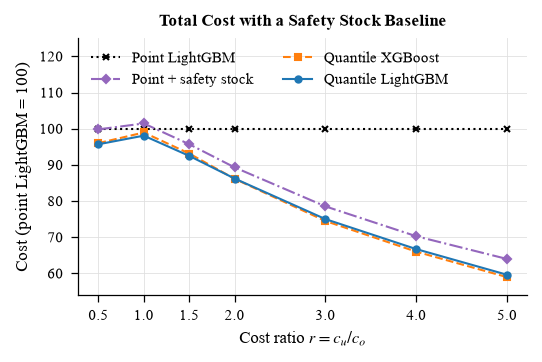

In [11]:
styles = {
    'Point LightGBM': dict(color='black', linestyle=':', marker='x'),
    'Safety stock (LightGBM + past errors)': dict(color='tab:purple', linestyle='-.', marker='D'),
    'Quantile XGBoost': dict(color='tab:orange', linestyle='--', marker='s'),
    'Quantile LightGBM': dict(color='tab:blue', linestyle='-', marker='o'),
}
labels = {'Point LightGBM': 'Point LightGBM', 'Safety stock (LightGBM + past errors)': 'Point + safety stock',
          'Quantile XGBoost': 'Quantile XGBoost', 'Quantile LightGBM': 'Quantile LightGBM'}

fig, ax = plt.subplots(figsize=(ONE_COL, 2.3))
for policy in policies:
    ax.plot(relative_cost.index, relative_cost[policy], markersize=3, label=labels[policy], **styles[policy])
ax.set_title('Total Cost with a Safety Stock Baseline')
ax.set_xlabel(r'Cost ratio $r = c_u / c_o$')
ax.set_ylabel('Cost (point LightGBM = 100)')
ax.set_xticks(COST_RATIOS)
ax.set_ylim(relative_cost.values.min() - 5, 125)
ax.legend(ncol=2, loc='upper left')
save_fig(fig, 'fig32_cost_with_safety_stock')
plt.show()

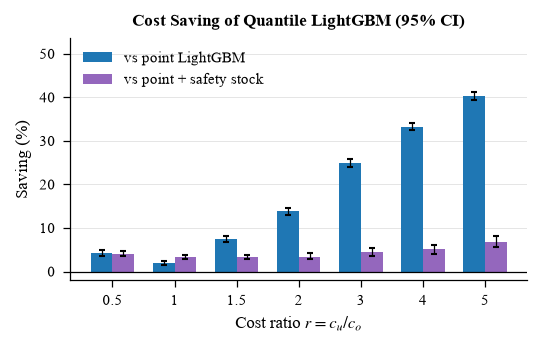

In [12]:
fig, ax = plt.subplots(figsize=(ONE_COL, 2.2))
width = 0.35
x = np.arange(len(COST_RATIOS))
for k, (base, color, label) in enumerate([('Point LightGBM', 'tab:blue', 'vs point LightGBM'),
                                          ('Safety stock (LightGBM + past errors)', 'tab:purple', 'vs point + safety stock')]):
    t = ci_table[ci_table['compared with'] == base]
    err = [t['saving %'] - t['95% CI low'], t['95% CI high'] - t['saving %']]
    ax.bar(x + (k - 0.5) * width, t['saving %'], width, yerr=err, capsize=1.5, color=color,
           error_kw=dict(lw=0.6), label=label)
ax.axhline(0, color='black', linewidth=0.6)
ax.set_title('Cost Saving of Quantile LightGBM (95% CI)')
ax.set_xlabel(r'Cost ratio $r = c_u / c_o$')
ax.set_ylabel('Saving (%)')
ax.set_xticks(x)
ax.set_xticklabels([str(r) for r in COST_RATIOS])
ax.set_ylim(min(-2, ci_table['95% CI low'].min() - 2), ci_table['95% CI high'].max() * 1.3)
ax.grid(axis='x', visible=False)
ax.legend(loc='upper left')
save_fig(fig, 'fig33_saving_confidence')
plt.show()

## 6. Save

In [13]:
check.round(3).to_csv('../results/tables/08_safety_stock_quantile_check.csv')
sim.to_csv('../results/tables/08_simulation_per_fold.csv', index=False)
relative_cost.round(2).to_csv('../results/tables/08_relative_cost.csv')
ci_table.to_csv('../results/tables/08_saving_confidence.csv', index=False)
dm_table.to_csv('../results/tables/08_diebold_mariano_corrected.csv', index=False)
print('saved')

saved


## Summary

**1. Stronger baseline (point forecast + safety stock).** The safety stock already gets most of the saving: at r = 3 it
costs 78.5 against 100 for the point forecast. But **quantile LightGBM is still cheaper at every cost ratio**:

| Cost ratio r | 0.5 | 1 | 1.5 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|---|---|
| Saving vs point LightGBM | 4.3% | 1.9% | 7.5% | 13.8% | 25.0% | 33.3% | 40.4% |
| Saving vs point + safety stock | 4.1% | 3.3% | 3.4% | 3.4% | 4.5% | 5.1% | 6.8% |
| 95% CI (vs safety stock) | 3.6-4.7 | 2.8-3.8 | 2.8-3.9 | 2.8-4.2 | 3.6-5.4 | 4.0-6.2 | 5.6-8.1 |

- **Why the quantile model wins:** the safety stock adds the same margin (in %) to every meal at a given horizon.
  The quantile model learns a **different margin for each meal and week** (small for stable meals, large for
  volatile or promoted ones). So at r = 3 it needs less extra food for almost the same service level:
  waste 24.0% vs 32.0% of demand, weeks with no shortage 73.1% vs 74.4%.
- The safety stock is slightly better calibrated (coverage 79.3% at $\tau$ = 0.8 vs 77.4%), but its pinball loss is
  higher at every level (e.g. 29.6 vs 28.1 at 0.8), so its forecasts are less sharp.

**2. Corrected Diebold-Mariano test.** Every conclusion from notebooks 05-07 stays the same with the corrected test:
tree models vs Linear Regression p < 0.001; LightGBM vs XGBoost still not different (p = 0.96); LightGBM vs Random
Forest p = 0.002; quantile vs point pinball p < 0.001. Quantile LightGBM vs the safety stock: **significant at every
cost ratio** (p between 0.00 and 0.03).

**3. Confidence intervals.** All savings have narrow 95% intervals that stay above zero (bootstrap over the 3,597 series).

**What this means for the paper:** most of the saving comes from **ordering at the cost-based level $\tau^*$ instead of
the point forecast** (newsvendor thinking); the quantile model adds a further, significant **3-7%** over a strong
safety-stock rule, by learning item-specific margins. This is a more careful and more convincing claim than
"40% cheaper than the point forecast".

Saved: `results/tables/08_safety_stock_quantile_check.csv`, `08_simulation_per_fold.csv`, `08_relative_cost.csv`,
`08_saving_confidence.csv`, `08_diebold_mariano_corrected.csv`, figures fig32 and fig33.